# Lab 8 · Variational circuits and their gradients

**Level 7 · Quantum Causal AI research** · Prerequisite lessons: L7-01 (Define the learning task), L7-02 (Variational circuits and parameter-shift gradients), L7-04 (Barren plateaus and trainability).

**What you'll learn**

- How a small parametrized circuit defines a model $f_{\boldsymbol\theta}(x)$. How to train it with a classical optimizer, as in hybrid quantum circuit learning [@mitarai].
- Why the parameter-shift rule gives exact gradients from two circuit runs [@schuld]. How it compares with finite differences when each run has shot noise.
- What a barren plateau looks like in a toy simulation: gradient variance that shrinks exponentially with the number of qubits [@plateaus].

:::{important} Scope
This lab is about quantum *machine learning* (variational algorithms). That is a different research program from quantum causal models and from indefinite causal order. Everything below is a classical simulation of small circuits. Nothing here demonstrates a quantum advantage.
:::

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/pozapas/quantum-causal-ai/blob/main/labs/08-variational-gradients.ipynb)

In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))

In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from qcai import science as s
from qcai.viz import show

np.set_printoptions(precision=4, suppress=True)

## 1 · The model and its exact gradient

The engine's model prepares $|\psi\rangle=R_Y(\theta_1)R_Z(x)R_Y(\theta_0)|0\rangle$ and returns $f_{\boldsymbol\theta}(x)=\langle\psi|Z|\psi\rangle$. Follow the Bloch vector through the three rotations and you get the closed form

$$
f_{\boldsymbol\theta}(x)=\cos\theta_0\cos\theta_1-\sin\theta_0\sin\theta_1\cos x .
$$

Take a gate $e^{-i\theta P/2}$ with a Pauli $P$. Its derivative is an exact finite difference with a *large* shift [@schuld]:

$$
\frac{\partial f}{\partial\theta_k}=\tfrac12\Big[f(\theta_k+\tfrac{\pi}{2})-f(\theta_k-\tfrac{\pi}{2})\Big].
$$

:::{note} Predict
Is the parameter-shift formula an approximation that improves as the shift shrinks, or exact at the shift $\pi/2$?
:::

In [3]:
def f_closed(t, x):
    return math.cos(t[0]) * math.cos(t[1]) - math.sin(t[0]) * math.sin(t[1]) * math.cos(x)

def grad_closed(t, x):
    return np.array([-math.sin(t[0]) * math.cos(t[1]) - math.cos(t[0]) * math.sin(t[1]) * math.cos(x),
                     -math.cos(t[0]) * math.sin(t[1]) - math.sin(t[0]) * math.cos(t[1]) * math.cos(x)])

g = np.random.default_rng(0)
for _ in range(300):
    t, x = g.uniform(-math.pi, math.pi, 2), g.uniform(-math.pi, math.pi)
    assert abs(s.vqc_expectation(t, x) - f_closed(t, x)) < 1e-12
    assert np.allclose(s.vqc_gradient(t, x), grad_closed(t, x), atol=1e-12)
print("closed form and exact parameter-shift gradient verified at 300 random points")

closed form and exact parameter-shift gradient verified at 300 random points


**Explain.** The parameter-shift rule is exact. It agrees with the analytic derivative to machine precision. The reason: $f$ is a sinusoid of each $\theta_k$ (period $2\pi$), and for a sinusoid this two-point formula is an identity.

## 2 · A regression task and its loss surface

We generate a target from hidden parameters $\boldsymbol\theta^\star=(1.1,\,0.7)$ on 15 inputs in $[-\pi,\pi]$. We fit it with the mean squared error

$$
L(\boldsymbol\theta)=\frac{1}{m}\sum_{j=1}^{m}\big(f_{\boldsymbol\theta}(x_j)-y_j\big)^2,\qquad
\nabla L=\frac{2}{m}\sum_j\big(f_{\boldsymbol\theta}(x_j)-y_j\big)\nabla f_{\boldsymbol\theta}(x_j).
$$

The target is *realizable* by construction, so the global minimum is $L=0$. Hover over the heatmap to read the loss.

In [4]:
theta_star = np.array([1.1, 0.7])
xs = np.linspace(-math.pi, math.pi, 15)
ys = np.array([s.vqc_expectation(theta_star, x) for x in xs])

def loss(t):
    return float(np.mean([(s.vqc_expectation(t, x) - y) ** 2 for x, y in zip(xs, ys)]))

def loss_grad(t):
    return sum(2 * (s.vqc_expectation(t, x) - y) * s.vqc_gradient(t, x) for x, y in zip(xs, ys)) / len(xs)

# gradient descent with exact parameter-shift gradients
t = np.array([0.3, -2.2]); lr = 0.4
path, losses = [t.copy()], [loss(t)]
for _ in range(80):
    t = t - lr * loss_grad(t)
    path.append(t.copy()); losses.append(loss(t))
path = np.array(path); losses = np.array(losses)
print(f"initial loss {losses[0]:.4f} -> final loss {losses[-1]:.2e} after {len(losses)-1} steps; final theta = {path[-1]}")
assert losses[-1] < 1e-6 and losses[-1] < losses[0]
# chain rule check of loss_grad against a central finite difference with a tiny step (no shot noise here)
e = 1e-6
fd = np.array([(loss(t + e * np.eye(2)[k]) - loss(t - e * np.eye(2)[k])) / (2 * e) for k in range(2)])
assert np.allclose(fd, loss_grad(t), atol=1e-8)

grid = np.linspace(-math.pi, math.pi, 61)
Lgrid = np.array([[loss((a, b)) for a in grid] for b in grid])
fig = go.Figure([
    go.Heatmap(x=grid, y=grid, z=Lgrid, colorscale="Viridis", colorbar=dict(title="loss"),
               hovertemplate="θ0=%{x:.2f}<br>θ1=%{y:.2f}<br>loss=%{z:.3f}<extra></extra>"),
    go.Scatter(x=path[:, 0], y=path[:, 1], mode="lines+markers", marker=dict(size=4, color="white"),
               line=dict(color="white"), name="gradient-descent path"),
    go.Scatter(x=[theta_star[0]], y=[theta_star[1]], mode="markers", marker=dict(symbol="x", size=12, color="red"), name="θ*"),
])
fig.update_layout(height=560, title="Loss landscape L(θ0, θ1) with the training path", xaxis_title="θ0", yaxis_title="θ1",
                  legend=dict(x=0.01, y=0.99, bgcolor="rgba(255,255,255,0.7)"))
show(fig)

initial loss 1.2777 -> final loss 8.01e-10 after 80 steps; final theta = [-0.6999 -1.1   ]


The loss surface has several equally good minima, because the model has symmetries. For example, $(\theta_0,\theta_1)\mapsto(\theta_1,\theta_0)$ leaves $f$ unchanged. The optimizer may therefore converge to a point other than $\boldsymbol\theta^\star$ with the same loss. The figure below replays training. Drag the slider to step through the optimization.

In [5]:
assert abs(loss(theta_star[::-1])) < 1e-12        # the swapped parameters fit equally well
xx = np.linspace(-math.pi, math.pi, 120)
frames_idx = list(range(0, 21)) + list(range(22, len(path), 4))
def fit_curve(t):
    return [s.vqc_expectation(t, x) for x in xx]

fig = make_subplots(rows=1, cols=2, subplot_titles=("model vs data", "training loss (log scale)"))
fig.add_trace(go.Scatter(x=xs, y=ys, mode="markers", name="data", marker=dict(color="black", size=8)), 1, 1)
fig.add_trace(go.Scatter(x=xx, y=fit_curve(path[0]), mode="lines", name="model", line=dict(color="crimson", width=3)), 1, 1)
fig.add_trace(go.Scatter(x=[0], y=[losses[0]], mode="lines+markers", name="loss", line=dict(color="#4c78a8")), 1, 2)
steps = [dict(method="restyle", label=str(i),
              args=[{"x": [xx.tolist(), list(range(i + 1))], "y": [fit_curve(path[i]), losses[: i + 1].tolist()]}, [1, 2]])
         for i in frames_idx]
fig.update_xaxes(title_text="x", row=1, col=1); fig.update_yaxes(range=[-1.1, 1.1], title_text="f(x)", row=1, col=1)
fig.update_xaxes(range=[0, len(path)], title_text="step", row=1, col=2)
fig.update_yaxes(type="log", range=[-9, 0.5], row=1, col=2)
fig.update_layout(height=480, title="Training with exact parameter-shift gradients (drag the slider)",
                  sliders=[dict(active=0, currentvalue=dict(prefix="step "), pad=dict(t=50), steps=steps)])
show(fig)

## 3 · Shot noise: parameter shift vs finite differences

On hardware, each expectation value is estimated from $N$ shots. With $\hat f=2n_0/N-1$ we have $\operatorname{Var}\hat f=(1-f^2)/N$. Here are two estimators of $\partial f/\partial\theta_0$. Each uses two circuit settings with $N$ shots each:

- parameter shift: $\hat g_{\rm PS}=\tfrac12\big[\hat f(\theta_0+\tfrac\pi2)-\hat f(\theta_0-\tfrac\pi2)\big]$, unbiased, variance $\le 1/(2N)$;
- central finite difference: $\hat g_{\rm FD}=\big[\hat f(\theta_0+h)-\hat f(\theta_0-h)\big]/(2h)$, variance $\approx(1-f^2)/(2h^2N)$, plus a bias of order $h^2$.

:::{note} Predict
Shrinking $h$ removes the finite-difference bias. What does it do to the variance?
:::

In [6]:
t0, x0 = np.array([0.4, 1.3]), 0.8
true_g = s.vqc_gradient(t0, x0)[0]
gen = np.random.default_rng(42)
reps = 4000
Ns = np.array([30, 100, 300, 1000, 3000, 10000])
hs = [0.01, 0.1, 0.5, 1.0]

def f_hat(t, N, size):
    p0 = (1 + s.vqc_expectation(t, x0)) / 2
    return 2 * gen.binomial(N, p0, size=size) / N - 1

def shifted(d):
    t = t0.copy(); t[0] += d; return t

rmse_ps, rmse_fd, var_ps, bound_ps = [], {h: [] for h in hs}, [], []
for N in Ns:
    gps = 0.5 * (f_hat(shifted(math.pi / 2), N, reps) - f_hat(shifted(-math.pi / 2), N, reps))
    rmse_ps.append(math.sqrt(np.mean((gps - true_g) ** 2)))
    var_ps.append(gps.var())
    fp, fm = s.vqc_expectation(shifted(math.pi / 2), x0), s.vqc_expectation(shifted(-math.pi / 2), x0)
    bound_ps.append(((1 - fp ** 2) + (1 - fm ** 2)) / (4 * N))          # exact variance of the PS estimator
    for h in hs:
        gfd = (f_hat(shifted(h), N, reps) - f_hat(shifted(-h), N, reps)) / (2 * h)
        rmse_fd[h].append(math.sqrt(np.mean((gfd - true_g) ** 2)))
rmse_ps = np.array(rmse_ps)
for N, v, b in zip(Ns, var_ps, bound_ps):
    assert abs(v - b) / b < 0.1 and b <= 1 / (2 * N)                    # empirical variance matches theory
for h in (0.01, 0.1, 0.5):
    assert np.all(rmse_ps < np.array(rmse_fd[h]))
print(f"true gradient {true_g:.4f}")
print("N      PS-RMSE   " + "  ".join(f"FD(h={h})" for h in hs))
for i, N in enumerate(Ns):
    print(f"{N:<6d} {rmse_ps[i]:.4f}    " + "  ".join(f"{rmse_fd[h][i]:.4f}  " for h in hs))
bias_h1 = (s.vqc_expectation(shifted(1.0), x0) - s.vqc_expectation(shifted(-1.0), x0)) / 2 - true_g
print(f"exact bias of FD at h=1: {bias_h1:+.4f} (equals (sin(1) - 1) * gradient = {(math.sin(1) - 1) * true_g:+.4f})")
assert abs(bias_h1 - (math.sin(1) - 1) * true_g) < 1e-12

fig = go.Figure([go.Scatter(x=Ns, y=rmse_ps, mode="lines+markers", name="parameter shift", line=dict(color="crimson", width=3)),
                 go.Scatter(x=Ns, y=rmse_fd[0.1], mode="lines+markers", name="finite difference", line=dict(color="#4c78a8", width=3)),
                 go.Scatter(x=Ns, y=1 / np.sqrt(2 * Ns), mode="lines", name="1/√(2N) bound for PS", line=dict(color="gray", dash="dot"))])
steps = [dict(method="restyle", label=str(h), args=[{"y": [rmse_fd[h]]}, [1]]) for h in hs]
fig.update_layout(height=480, title="Gradient error vs shots per circuit (4000 repetitions each)", xaxis_type="log", yaxis_type="log",
                  xaxis_title="shots per circuit N", yaxis_title="RMSE of the gradient estimate",
                  sliders=[dict(active=1, currentvalue=dict(prefix="finite-difference step h = "), pad=dict(t=50), steps=steps)])
show(fig)

true gradient -0.7225
N      PS-RMSE   FD(h=0.01)  FD(h=0.1)  FD(h=0.5)  FD(h=1.0)
30     0.0887    12.8073    1.3290    0.2415    0.1547  
100    0.0480    6.9377    0.7003    0.1363    0.1271  
300    0.0278    4.1133    0.4048    0.0814    0.1191  
1000   0.0154    2.2600    0.2223    0.0514    0.1160  
3000   0.0091    1.2775    0.1285    0.0385    0.1149  
10000  0.0050    0.6847    0.0695    0.0322    0.1146  
exact bias of FD at h=1: +0.1145 (equals (sin(1) - 1) * gradient = +0.1145)


**Explain.** Shrinking $h$ removes bias but *amplifies* shot noise like $1/h$. Tiny steps are useless on noisy hardware. A large step reduces noise but adds bias. The code computes the exact bias at $h=1$ as $(\sin 1-1)\,\partial_{\theta_0}f$. Parameter shift gets both: it is unbiased, and its shift is large ($\pi/2$). In this example its RMSE was below the finite-difference RMSE for $h\in\{0.01,0.1,0.5\}$ at every $N$ tested. That comparison is specific to this circuit and point. The code reports the $h=1$ column without a claim.

## 4 · Barren plateaus in a toy simulation

McClean *et al.* studied wide classes of randomly initialized parametrized circuits, those that behave like unitary 2-designs [@plateaus]. They showed that, for these circuits, the probability that a gradient component is non-negligible is exponentially small in the number of qubits. We reproduce the *trend* with a small statevector simulator:

- $n$ qubits start in $R_Y(\pi/4)^{\otimes n}|0\rangle$;
- each of $L=5n$ layers applies a random Pauli rotation ($R_X$, $R_Y$, or $R_Z$, uniformly) with a uniformly random angle to each qubit, then a ladder of controlled-Z gates;
- the cost is the global projector $C=|\langle 0^n|\psi\rangle|^2$;
- we estimate $\operatorname{Var}[\partial C/\partial\theta_1]$ over 300 random circuits for $n=2,\dots,8$, using the exact parameter-shift rule.

First, we check the simulator against a dense matrix construction and against a finite difference.

In [7]:
GATES = (s.rx, s.ry, s.rz)

def apply_1q(psi, U, q, n):
    psi = np.moveaxis(np.tensordot(U, psi.reshape([2] * n), axes=([1], [q])), 0, q)
    return psi.reshape(-1)

def cz_ladder_diag(n):
    idx = np.arange(2 ** n); d = np.ones(2 ** n)
    for q in range(n - 1):
        d *= np.where(((idx >> (n - 1 - q)) & 1) & ((idx >> (n - 2 - q)) & 1), -1, 1)
    return d

def circuit_state(thetas, axes, n, L, czd):
    psi = np.zeros(2 ** n, complex); psi[0] = 1
    for q in range(n):
        psi = apply_1q(psi, s.ry(math.pi / 4), q, n)
    k = 0
    for _ in range(L):
        for q in range(n):
            psi = apply_1q(psi, GATES[axes[k]](thetas[k]), q, n); k += 1
        psi = czd * psi
    return psi

def cost(thetas, axes, n, L, czd):
    return abs(circuit_state(thetas, axes, n, L, czd)[0]) ** 2

def ps_grad0(thetas, axes, n, L, czd):
    p, m = thetas.copy(), thetas.copy(); p[0] += math.pi / 2; m[0] -= math.pi / 2
    return 0.5 * (cost(p, axes, n, L, czd) - cost(m, axes, n, L, czd))

# validation 1: dense construction for n = 3, L = 2
n, L = 3, 2
g = np.random.default_rng(7)
th, ax = g.uniform(0, 2 * math.pi, n * L), g.integers(3, size=n * L)
CZ = np.diag(cz_ladder_diag(n)).astype(complex)
U = s.kron(*[s.ry(math.pi / 4)] * n)
k = 0
for _ in range(L):
    U = s.kron(*[GATES[ax[k + q]](th[k + q]) for q in range(n)]) @ U; k += n
    U = CZ @ U
assert np.allclose(U[:, 0], circuit_state(th, ax, n, L, cz_ladder_diag(n)))
# validation 2: parameter shift equals a tiny central finite difference (exact arithmetic, no shots)
e = 1e-6
th_p, th_m = th.copy(), th.copy(); th_p[0] += e; th_m[0] -= e
fd = (cost(th_p, ax, n, L, cz_ladder_diag(n)) - cost(th_m, ax, n, L, cz_ladder_diag(n))) / (2 * e)
assert abs(fd - ps_grad0(th, ax, n, L, cz_ladder_diag(n))) < 1e-8
print("statevector simulator and parameter-shift gradient validated")

statevector simulator and parameter-shift gradient validated


n = 2: Var[dC/dtheta_1] = 1.326e-02   mean = +3.0e-03
n = 3: Var[dC/dtheta_1] = 5.710e-03   mean = +6.3e-03
n = 4: Var[dC/dtheta_1] = 1.560e-03   mean = +3.4e-04
n = 5: Var[dC/dtheta_1] = 3.301e-04   mean = +3.0e-04
n = 6: Var[dC/dtheta_1] = 7.586e-05   mean = -3.0e-04
n = 7: Var[dC/dtheta_1] = 2.549e-05   mean = -1.9e-04
n = 8: Var[dC/dtheta_1] = 5.866e-06   mean = -1.2e-04
fitted log2-variance slope: -1.91 per qubit  (variance shrinks by about x3.8 per added qubit)


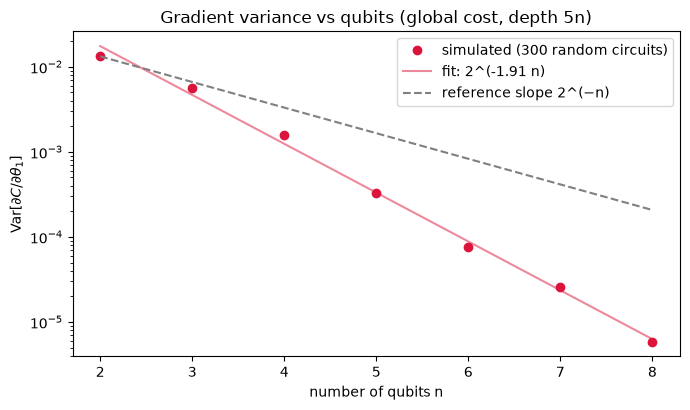

In [8]:
qubits = np.arange(2, 9)
samples = 300
variances, means = [], []
for n in qubits:
    L = 5 * n
    czd = cz_ladder_diag(n)
    g = np.random.default_rng(100 + n)
    grads = np.array([ps_grad0(g.uniform(0, 2 * math.pi, n * L), g.integers(3, size=n * L), n, L, czd) for _ in range(samples)])
    variances.append(grads.var()); means.append(grads.mean())
variances = np.array(variances)
slope, intercept = np.polyfit(qubits, np.log2(variances), 1)
for n, v, m in zip(qubits, variances, means):
    print(f"n = {n}: Var[dC/dtheta_1] = {v:.3e}   mean = {m:+.1e}")
print(f"fitted log2-variance slope: {slope:.2f} per qubit  (variance shrinks by about x{2 ** -slope:.1f} per added qubit)")
assert slope < -1.0                                   # clear exponential decay in this toy
assert variances[-1] < variances[0] / 100
assert np.all(np.diff(np.log(variances)) < 0)         # monotone over n = 2..8 in this run
for v, m in zip(variances, means):
    assert abs(m) < 4 * math.sqrt(v / samples)          # mean gradient is zero within sampling error

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.semilogy(qubits, variances, "o", color="crimson", label="simulated (300 random circuits)")
ax.semilogy(qubits, 2 ** (intercept + slope * qubits), "-", color="crimson", alpha=0.5, label=f"fit: 2^({slope:.2f} n)")
ax.semilogy(qubits, variances[0] * 2.0 ** (-(qubits - 2)), "--", color="gray", label="reference slope 2^(−n)")
ax.set_xlabel("number of qubits n"); ax.set_ylabel(r"Var[$\partial C/\partial\theta_1$]")
ax.set_title("Gradient variance vs qubits (global cost, depth 5n)")
ax.legend(); plt.tight_layout(); plt.show()

**Explain.** The gradient mean is essentially zero. Its variance falls exponentially with $n$ in this toy; the code asserts a fitted slope steeper than $2^{-n}$. A gradient that small needs many shots to resolve. From Section 3, a parameter-shift estimate with $N$ shots has standard deviation up to $1/\sqrt{2N}$. To resolve a gradient of typical size $\sqrt{\operatorname{Var}}$ you need $N\gtrsim 1/(2\operatorname{Var})$ shots, and that number grows exponentially in $n$.

**What this simulation does not establish.** We did not check that these circuits form a 2-design. We did not separate the effect of depth from the effect of the global cost. And seven system sizes cannot pin down an asymptotic rate.

:::{note} Noise-induced plateaus
Wang *et al.* prove a second mechanism, different in concept. Under local Pauli noise, gradients vanish exponentially in $n$ when the circuit depth grows linearly with $n$ [@noise]. We do not simulate noise here.
:::

## Going deeper: why the shift rule is exact

Let $f(\theta)=\langle\psi|U^\dagger(\theta)\,O\,U(\theta)|\psi\rangle$ with $U(\theta)=e^{-i\theta P/2}$ and $P^2=I$. Then $U(\theta)=\cos\tfrac\theta2\,I-i\sin\tfrac\theta2\,P$, so $f(\theta)=a+b\cos\theta+c\sin\theta$ for constants $a,b,c$. For any such function,

$$
\tfrac12\big[f(\theta+\tfrac\pi2)-f(\theta-\tfrac\pi2)\big]=-b\sin\theta+c\cos\theta=f'(\theta).
$$

The same argument fails for generators with more than two distinct eigenvalues. Schuld et al. handle such gates by conditioning a single gate on an ancilla [@schuld]. Later work derives rules with more shifts.

In [9]:
# Fit a + b cos + c sin to f(theta_0) at fixed theta_1, x and verify the identity on the fitted coefficients
tt = np.linspace(0, 2 * math.pi, 9)
vals = np.array([s.vqc_expectation((t, 0.9), 0.4) for t in tt])
A = np.c_[np.ones_like(tt), np.cos(tt), np.sin(tt)]
(a, b, c), res, *_ = np.linalg.lstsq(A, vals, rcond=None)
assert np.allclose(A @ [a, b, c], vals, atol=1e-12)            # f really is a single sinusoid in theta_0
for t in np.linspace(0, 2 * math.pi, 13):
    assert abs(s.vqc_gradient((t, 0.9), 0.4)[0] - (-b * math.sin(t) + c * math.cos(t))) < 1e-12
print(f"f(theta_0) = {a:.4f} + {b:.4f} cos + {c:.4f} sin  (exact fit)")

f(theta_0) = -0.0000 + 0.6216 cos + -0.7215 sin  (exact fit)


## Exercises

:::{admonition} Exercise: :label: lab08-ex1
:class: tip
Using the closed form, show that $f_{\boldsymbol\theta}(x)$ can only produce functions of the form $\alpha+\beta\cos x$. Which target functions can this model never fit?
:::

:::{dropdown} Solution
$f=\cos\theta_0\cos\theta_1-(\sin\theta_0\sin\theta_1)\cos x$: so $\alpha=\cos\theta_0\cos\theta_1$ and $\beta=-\sin\theta_0\sin\theta_1$. It can never fit $\sin x$, $\cos 2x$, or any function that is not even in $x$. More expressive models re-upload $x$ several times.
:::

:::{admonition} Exercise: :label: lab08-ex2
:class: tip
With $N=1000$ shots per circuit, bound the standard deviation of a single parameter-shift gradient estimate.
:::

:::{dropdown} Solution
$\operatorname{Var}\le 1/(2N)=5\times10^{-4}$, so the standard deviation is at most $\sqrt{5\times10^{-4}}\approx0.022$.
:::

:::{admonition} Exercise: :label: lab08-ex3
:class: tip
Use the simulated variance at $n=8$. Estimate how many shots per circuit you need before the shot noise of a parameter-shift estimate is no larger than the typical gradient size.
:::

:::{dropdown} Solution
Require $1/\sqrt{2N}\le\sqrt{\operatorname{Var}}$, i.e. $N\ge 1/(2\operatorname{Var})$. The check cell computes this number from the simulated variance. It is in the tens of thousands, compared with a few tens at $n=2$.
:::

## Check yourself

In [10]:
g = np.random.default_rng(1)
for _ in range(50):
    t = g.uniform(-math.pi, math.pi, 2)
    alpha, beta = math.cos(t[0]) * math.cos(t[1]), -math.sin(t[0]) * math.sin(t[1])
    for x in np.linspace(-math.pi, math.pi, 7):
        assert abs(s.vqc_expectation(t, x) - (alpha + beta * math.cos(x))) < 1e-12
        assert abs(s.vqc_expectation(t, x) - s.vqc_expectation(t, -x)) < 1e-12     # even in x
assert abs(math.sqrt(1 / (2 * 1000)) - 0.02236) < 1e-5
N_needed = {int(n): math.ceil(1 / (2 * v)) for n, v in zip(qubits, variances)}
print("shots per circuit needed so PS noise <= typical gradient size:", N_needed)
assert N_needed[8] > 10_000 and N_needed[2] < 100
print("All checks passed.")

shots per circuit needed so PS noise <= typical gradient size: {2: 38, 3: 88, 4: 321, 5: 1515, 6: 6592, 7: 19612, 8: 85245}
All checks passed.


## Limits of this model

The sizes are toys: one qubit for training, at most eight for the plateau study. Asymptotic statements belong to the cited proofs, not to these plots.

The target is realizable. The model itself generated the data. Real learning tasks rarely work that way, and a good fit says nothing about generalization.

The noise is idealized. We simulate only binomial shot noise. Gate errors, readout errors, and drift are absent.

We used one random ensemble. The plateau result depends on the circuit family, depth, cost function, and initialization. Other choices (local costs, shallow or structured circuits) can behave differently.

We make no advantage claim. Every number here was computed classically in seconds. Nothing shows that a quantum model learns better than a classical one.